In [1]:
%load_ext autoreload
%autoreload 2
import matplotlib.pyplot as plt, seaborn as sns
from ss_utils import *
df = load_data(".")   # the folder with train.csv and test.csv

In [2]:
IMPUTE, GROUPS = "logic", ("G1", "G2", "G3", "G4")   # adjust from E1/E2
X, y, g, X_te, ids, _ = build(df, impute=IMPUTE, groups=GROUPS)
FIXED = dict(n_estimators=400, learning_rate=0.03, num_leaves=15,
             subsample=0.8, subsample_freq=1, colsample_bytree=0.8)

In [3]:
r_group = run_cv("lgbm", X, y, g, params=FIXED, scheme="group")
r_plain = run_cv("lgbm", X, y, g, params=FIXED, scheme="plain")
log_result("E3-group", "E3 CV scheme", "StratifiedGroupKFold", "lgbm", r_group)
log_result("E3-plain", "E3 CV scheme", "StratifiedKFold", "lgbm", r_plain)
make_submission(ids, fit_predict_test("lgbm", X, y, X_te, params=FIXED), "E3_lgbm_fixed")

lgbm    CV acc = 0.8127 ± 0.0093  (oof 0.8124, 13.9s)
lgbm    CV acc = 0.8147 ± 0.0062  (oof 0.8138, 12.5s)
Saved submissions/E3_lgbm_fixed.csv: 4277 rows, 0.521 predicted True


'submissions/E3_lgbm_fixed.csv'

In [4]:
LB = 0.80710 # my public score from Kaggle

log = pd.read_csv(LOG_PATH)
log.loc[log.run_id.isin(["E3-group", "E3-plain"]), "lb_score"] = LB
log.to_csv(LOG_PATH, index=False)

e3 = log[log.run_id.isin(["E3-group", "E3-plain"])].copy()
e3["CV − LB gap"] = (e3.cv_mean - e3.lb_score).round(4)
e3[["run_id", "description", "cv_mean", "cv_std", "lb_score", "CV − LB gap"]]

,run_id,description,cv_mean,cv_std,lb_score,CV − LB gap
17,E3-group,StratifiedGroupKFold,0.81273,0.00931,0.8071,0.0056
18,E3-plain,StratifiedKFold,0.81468,0.00616,0.8071,0.0076


In [5]:
e4 = {}
for m in ["logreg", "rf", "mlp", "lgbm", "xgb", "cat"]:
    e4[m] = run_cv(m, X, y, g)
    log_result(f"E4-{m}-default", "E4 models", "default params", m, e4[m])

logreg  CV acc = 0.7980 ± 0.0092  (oof 0.7980, 1.7s)
rf      CV acc = 0.8021 ± 0.0083  (oof 0.8038, 16.6s)
mlp     CV acc = 0.7988 ± 0.0086  (oof 0.8051, 5.2s)
lgbm    CV acc = 0.8130 ± 0.0087  (oof 0.8142, 7.6s)
xgb     CV acc = 0.8041 ± 0.0076  (oof 0.8107, 3.9s)
cat     CV acc = 0.8149 ± 0.0072  (oof 0.8169, 41.2s)


In [6]:
import optuna, json
optuna.logging.set_verbosity(optuna.logging.WARNING)

SPACES = {
  "lgbm": lambda t: dict(
      n_estimators=t.suggest_int("n_estimators", 200, 1500, step=100),
      learning_rate=t.suggest_float("learning_rate", 0.01, 0.1, log=True),
      num_leaves=t.suggest_int("num_leaves", 8, 64),
      min_child_samples=t.suggest_int("min_child_samples", 10, 100),
      subsample=t.suggest_float("subsample", 0.6, 1.0), subsample_freq=1,
      colsample_bytree=t.suggest_float("colsample_bytree", 0.4, 1.0),
      reg_lambda=t.suggest_float("reg_lambda", 1e-3, 10, log=True)),
  "xgb": lambda t: dict(
      n_estimators=t.suggest_int("n_estimators", 200, 1500, step=100),
      learning_rate=t.suggest_float("learning_rate", 0.01, 0.1, log=True),
      max_depth=t.suggest_int("max_depth", 3, 8),
      min_child_weight=t.suggest_float("min_child_weight", 1, 20, log=True),
      subsample=t.suggest_float("subsample", 0.6, 1.0),
      colsample_bytree=t.suggest_float("colsample_bytree", 0.4, 1.0),
      reg_lambda=t.suggest_float("reg_lambda", 1e-3, 10, log=True)),
  "cat": lambda t: dict(
      iterations=t.suggest_int("iterations", 300, 1500, step=100),
      learning_rate=t.suggest_float("learning_rate", 0.01, 0.1, log=True),
      depth=t.suggest_int("depth", 4, 8),
      l2_leaf_reg=t.suggest_float("l2_leaf_reg", 1, 10, log=True),
      random_strength=t.suggest_float("random_strength", 0.1, 5, log=True)),
}

def tune(model, n_trials, timeout=None):
    def objective(trial):
        return run_cv(model, X, y, g, params=SPACES[model](trial), seeds=(0,), verbose=False)["mean"]
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=0))
    study.optimize(objective, n_trials=n_trials, timeout=timeout, show_progress_bar=True)
    best = SPACES[model](optuna.trial.FixedTrial(study.best_params))
    json.dump(best, open(f"results/best_{model}.json", "w"), indent=1)
    study.trials_dataframe().to_csv(f"results/optuna_{model}.csv", index=False)
    return best, study

best, studies = {}, {}
best["lgbm"], studies["lgbm"] = tune("lgbm", 100)
best["xgb"],  studies["xgb"]  = tune("xgb", 100)
best["cat"],  studies["cat"]  = tune("cat", 50, timeout=3600)

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

lgbm    CV acc = 0.8113 ± 0.0076  (oof 0.8125, 49.7s)
lgbm tuned - lgbm default: -0.0016 accuracy (better on 6/15 folds), p = 0.263
xgb     CV acc = 0.8117 ± 0.0087  (oof 0.8121, 12.7s)
xgb tuned - xgb default: +0.0076 accuracy (better on 14/15 folds), p = 0.000
cat     CV acc = 0.8150 ± 0.0082  (oof 0.8154, 45.6s)
cat tuned - cat default: +0.0001 accuracy (better on 6/15 folds), p = 0.899


,Model,CV accuracy,Time (s)
0,logreg,0.7980 ± 0.0092,1.7
1,rf,0.8021 ± 0.0083,16.6
2,mlp,0.7988 ± 0.0086,5.2
3,lgbm,0.8130 ± 0.0087,7.6
4,xgb,0.8041 ± 0.0076,3.9
5,cat,0.8149 ± 0.0072,41.2
6,lgbm_tuned,0.8113 ± 0.0076,49.7
7,xgb_tuned,0.8117 ± 0.0087,12.7
8,cat_tuned,0.8150 ± 0.0082,45.6


/var/folders/b9/5sf3kgmx527b5_36fv3l82w00000gn/T/ipykernel_13670/3400094315.py:10: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_optimization_history(studies["lgbm"])


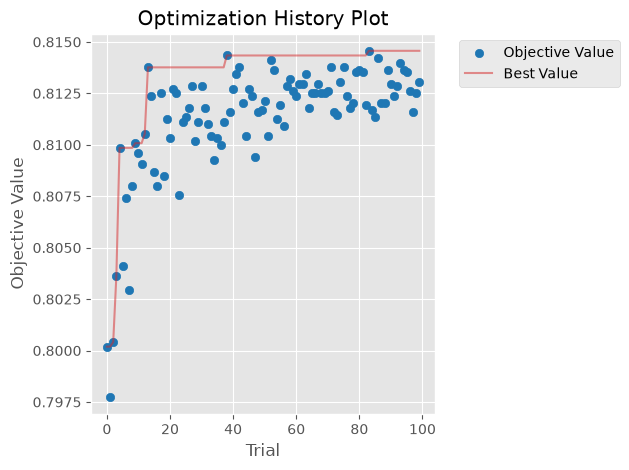

In [7]:
for m in ["lgbm", "xgb", "cat"]:
    e4[m + "_tuned"] = r = run_cv(m, X, y, g, params=best[m])
    log_result(f"E4-{m}-tuned", "E4 models", "Optuna-tuned", m, r)
    paired_test(e4[m], r, f"{m} default", f"{m} tuned")

table_e4 = pd.DataFrame([{"Model": k, "CV accuracy": f"{v['mean']:.4f} ± {v['std']:.4f}",
                          "Time (s)": v["seconds"]} for k, v in e4.items()])
table_e4.to_latex("results/e4_models.tex", index=False); display(table_e4)

optuna.visualization.matplotlib.plot_optimization_history(studies["lgbm"])
plt.savefig("figures/fig_optuna_lgbm.png", dpi=200, bbox_inches="tight")

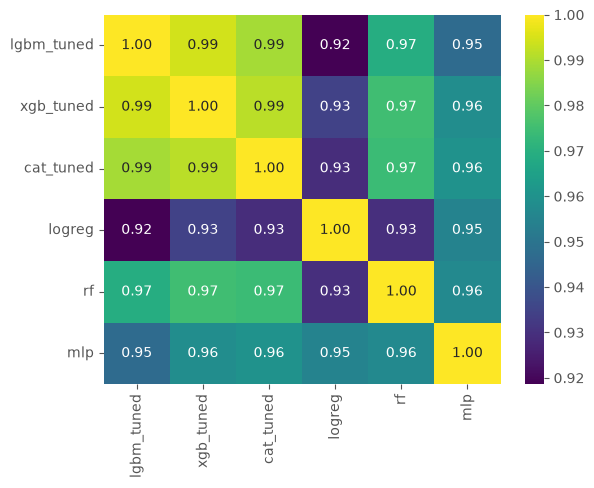

,Method,OOF accuracy
0,single lgbm_tuned,0.8125
1,single xgb_tuned,0.8121
2,single cat_tuned,0.8154
3,simple average,0.8148
4,"weighted {'lgbm_tuned': 0.0, 'xgb_tuned': 0.2,...",0.8171
5,stacking (logistic regression),0.8165


In [8]:
import itertools
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict

GB = ["lgbm_tuned", "xgb_tuned", "cat_tuned"]
oof = pd.DataFrame({k: e4[k]["oof"] for k in e4})
oof.to_csv("results/oof.csv", index=False)          # used again in 05_analysis
oof.corr().round(3).to_csv("results/e5_oof_correlation.csv")
sns.heatmap(oof[GB + ["logreg", "rf", "mlp"]].corr(), annot=True, fmt=".2f", cmap="viridis")
plt.savefig("figures/fig_oof_corr.png", dpi=200, bbox_inches="tight"); plt.show()

acc = lambda p: accuracy_score(y, p > 0.5)
rows = [{"Method": f"single {k}", "OOF accuracy": acc(oof[k])} for k in GB]
rows.append({"Method": "simple average", "OOF accuracy": acc(oof[GB].mean(axis=1))})

best_w, best_acc = None, 0
for w in itertools.product(np.arange(0, 1.01, 0.1), repeat=len(GB)):
    if abs(sum(w) - 1) < 1e-9 and acc(oof[GB].to_numpy() @ np.array(w)) > best_acc:
        best_acc, best_w = acc(oof[GB].to_numpy() @ np.array(w)), np.round(w, 1)
rows.append({"Method": f"weighted {dict(zip(GB, best_w))}", "OOF accuracy": best_acc})

folds = get_folds(y, g, "group", seed=42)
stack = cross_val_predict(LogisticRegression(), oof[GB], y, cv=folds, method="predict_proba")[:, 1]
rows.append({"Method": "stacking (logistic regression)", "OOF accuracy": acc(stack)})
table_e5 = pd.DataFrame(rows).round(4); table_e5.to_latex("results/e5_ensembles.tex", index=False)
table_e5

In [9]:
p = {m: fit_predict_test(m, X, y, X_te, params=best[m]) for m in ["lgbm", "xgb", "cat"]}
make_submission(ids, p["cat"], "E4_cat_tuned")
make_submission(ids, np.mean([p["lgbm"], p["xgb"], p["cat"]], axis=0), "E5_avg3")
pd.DataFrame(p).to_csv("results/test_probs.csv", index=False)   

Saved submissions/E4_cat_tuned.csv: 4277 rows, 0.510 predicted True
Saved submissions/E5_avg3.csv: 4277 rows, 0.512 predicted True


In [10]:
FOLDS = [va for s in (0, 1, 2) for _, va in get_folds(y, g, "group", seed=s)]   # same 15 folds as run_cv

def score_oof(p):
    folds = np.array([accuracy_score(y[va], p[va] > 0.5) for va in FOLDS])
    return {"mean": folds.mean(), "std": folds.std(), "folds": folds,
            "oof_acc": accuracy_score(y, p > 0.5), "seconds": 0}

oof = pd.read_csv("results/oof.csv")
GB = ["lgbm_tuned", "xgb_tuned", "cat_tuned"]
cands = {c: oof[c].to_numpy() for c in oof.columns}
cands["avg3_tuned"] = oof[GB].mean(axis=1).to_numpy()
cands["cat_default+tuned"] = oof[["cat", "cat_tuned"]].mean(axis=1).to_numpy()
res5 = {k: score_oof(v) for k, v in cands.items()}

table_cmp = (pd.DataFrame([{"Candidate": k, "CV acc": round(r["mean"], 4), "± std": round(r["std"], 4)}
                           for k, r in res5.items()])
             .sort_values("CV acc", ascending=False))
table_cmp.to_latex("results/e5_candidates.tex", index=False)
display(table_cmp)

paired_test(res5["cat_tuned"], res5["avg3_tuned"], "cat tuned", "avg3")
paired_test(res5["cat"], res5["cat_tuned"], "cat default", "cat tuned")
paired_test(res5["lgbm"], res5["lgbm_tuned"], "lgbm default", "lgbm tuned")

log_result("E5-avg3", "E5 ensembles", "mean of lgbm/xgb/cat tuned", "ensemble", res5["avg3_tuned"])
log_result("E5-cat2", "E5 ensembles", "mean of cat default + cat tuned", "ensemble", res5["cat_default+tuned"])

,Candidate,CV acc,± std
5,cat,0.8169,0.0060
10,cat_default+tuned,0.8162,0.0062
8,cat_tuned,0.8154,0.0064
9,avg3_tuned,0.8148,0.0079
3,lgbm,0.8142,0.0075
6,lgbm_tuned,0.8125,0.0076
7,xgb_tuned,0.8121,0.0078
4,xgb,0.8107,0.0070
2,mlp,0.8051,0.0082
1,rf,0.8038,0.0082


avg3 - cat tuned: -0.0006 accuracy (better on 6/15 folds), p = 0.623
cat tuned - cat default: -0.0015 accuracy (better on 4/15 folds), p = 0.057
lgbm tuned - lgbm default: -0.0017 accuracy (better on 3/15 folds), p = 0.030


In [11]:
make_submission(ids, fit_predict_test("cat", X, y, X_te), "E4_cat_default")

Saved submissions/E4_cat_default.csv: 4277 rows, 0.512 predicted True


'submissions/E4_cat_default.csv'

In [12]:
import json
best = {m: json.load(open(f"results/best_{m}.json")) for m in ["lgbm", "xgb", "cat"]}
SEEDS = tuple(range(10))
p_cat_def   = fit_predict_test("cat", X, y, X_te, seeds=SEEDS)
p_cat_tuned = fit_predict_test("cat", X, y, X_te, params=best["cat"], seeds=SEEDS)
make_submission(ids, (p_cat_def + p_cat_tuned) / 2, "E5_cat2_10seeds")

Saved submissions/E5_cat2_10seeds.csv: 4277 rows, 0.513 predicted True


'submissions/E5_cat2_10seeds.csv'

In [13]:
def tune3(model, n_trials, timeout=None):
    def objective(trial):
        return run_cv(model, X, y, g, params=SPACES[model](trial), seeds=(0, 1, 2), verbose=False)["mean"]
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=1))
    study.enqueue_trial({"iterations": 1000, "learning_rate": 0.03, "depth": 6,
                         "l2_leaf_reg": 3.0, "random_strength": 1.0})     # roughly CatBoost's defaults
    study.optimize(objective, n_trials=n_trials, timeout=timeout, show_progress_bar=True)
    best = SPACES[model](optuna.trial.FixedTrial(study.best_params))
    json.dump(best, open(f"results/best_{model}_3seed.json", "w"), indent=1)
    return best, study

best_cat3, study_cat3 = tune3("cat", 30, timeout=2400)
r = run_cv("cat", X, y, g, params=best_cat3)
log_result("E4-cat-tuned3", "E4 models", "Optuna, 3-seed objective", "cat", r)

  0%|          | 0/30 [00:00<?, ?it/s]

cat     CV acc = 0.8159 ± 0.0080  (oof 0.8172, 41.6s)


In [14]:
import json
best_cat3 = json.load(open("results/best_cat_3seed.json"))
p_cat3 = fit_predict_test("cat", X, y, X_te, params=best_cat3, seeds=tuple(range(10)))
make_submission(ids, p_cat3, "E4_cat_tuned3_10seeds")

# how different is it from your best public submission so far?
old = pd.read_csv("submissions/E4_cat_default.csv")["Transported"]
new = pd.read_csv("submissions/E4_cat_tuned3_10seeds.csv")["Transported"]
print("predictions that differ from E4_cat_default:", int((old != new).sum()))

Saved submissions/E4_cat_tuned3_10seeds.csv: 4277 rows, 0.513 predicted True
predictions that differ from E4_cat_default: 71
